# Second Practical work

This is second practical work skeleton.

It is divided in 3 parts_

1.   Python module load section: load all the needed modules
2.   Google Drive access and mounting
3.   Host load data
4.   GPU load





## Module load section
We will install the pycuda module in the colaboratory environment, to combine python and CUDA in our code. Because pycuda is not available by default, this task can take a few minutes.

As well we load numpy and matplotlib modules.

In [104]:
#!pip install pycuda

We import the Python modules which we will use in the notebook (numpy, pycuda and time module) 

In [105]:
import  numpy  as  np
import  pycuda.autoinit
from    pycuda.compiler import SourceModule
import  pycuda.driver as  drv
import  pycuda.gpuarray as  gpuarray
from sys import getsizeof
import time

In [106]:
%pylab inline
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cProfile

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/opt/venv/lib/python3.10/site-packages/IPython/core/magics/pylab.py:166: UserWarning: pylab import has clobbered these variables: ['axes']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


## Mount Google Drive and access grant
We use Google API to allow access to our Google Drive.

For security and privacy reasons, this permission is temporally, and will be requested every time you restart the notebook. 

Your Google Drive will be mounted in the "/content/drive" folder. The first Folder will be "My Drive".

You have to copy your images to a folder in the "My Drive" folder in your Google Drive.

To check your available files, use the cell indicated as "**List Files in Folder**"

In [107]:
from os.path import join
# from google.colab import drive
# drive.mount("/content/drive")

IMG_DIR = "Practical Work 01/Test Images"

In [108]:
# MYDRIVE="/content/drive/My Drive/"

**List Files in Folders**

In [109]:
#!ls /content/drive/My\ Drive/images
!ls "Practical Work 01/Test Images"

chess.jpg  cloudsonjupi.jpg  digits.jpg  fence.jpg  hand-x-ray.jpg


We define a variable IMAGE which is constructed joining the "MYDRIVE" varible plus the final path to your image.

In [110]:
IMAGE = join(IMG_DIR, "chess.jpg")

In [111]:
print("Image to load: {0}".format(IMAGE))

Image to load: Practical Work 01/Test Images/chess.jpg


Loads an image in a numpy variable, and show.

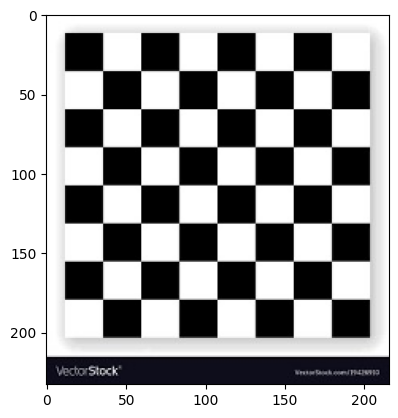

In [112]:
image=np.array(Image.open(IMAGE))
plt.figure()
plt.imshow(image)

# FILTER KERNEL

Here you have to define your `image_filter` GPU kernel.

* The kernel works on **one layer (channel) of the image**, a 2D matrix stored row by row: element (row, col) is at `row * width + col`.
* Block of 16 x 16 threads, one thread per output pixel. Grid: `ceil(width/16) x ceil(height/16)`.
* Use **tiled (shared) memory** with coalesced loads: a 2D shared array `tile[TILE][TILE]` (TILE = 16 + 5 - 1 = 20), indexed `tile[y][x]` as in numpy. Borders are replicated with `min`/`max`, without `if`.
* Copy the **filter mask to shared memory** too (`smask[5][5]`, indexed `smask[i][j]`), so the threads do not read it from global memory in every iteration.
* The kernel always computes the **correlation** and stores the raw sum: no clipping and no branches. Convolution, normalisation and clipping are done in Python.
* `filtered_img` is padded to `H16 x W16` (multiples of 16), so every thread writes without checking bounds. `W16 = gridDim.x * 16`.
* All integer parameters and indices are **signed** `int`.

In [113]:
kernel = SourceModule("""
#define BLOCK    16                       // Block size: BLOCK x BLOCK threads, one thread per output pixel
#define MASK_MAX 5                        // Maximum mask size (5x5)
#define TILE     (BLOCK + MASK_MAX - 1)   // Tile side: 20 for BLOCK = 16

__global__ void image_filter(float *image,          // Source image LAYER (one channel), height x width, float32
                             float *filtered_img,   // Target layer, PADDED to H16 x W16 (multiples of BLOCK), float32
                             float *mask,           // Filter mask, mask_h x mask_w, float32 (row-major)
                             int width,             // Image number of columns
                             int height,            // Image number of rows
                             int mask_w,            // Mask number of columns (odd, <= 5)
                             int mask_h)            // Mask number of rows    (odd, <= 5)
{
    // Shared memory, 2D arrays indexed [row][column] as in numpy:
    __shared__ float tile[TILE][TILE];           // tile[y][x]: image block + halo
    __shared__ float smask[MASK_MAX][MASK_MAX];  // smask[i][j]: filter mask

    // Used area: tile (BLOCK + mask_h - 1) rows x (BLOCK + mask_w - 1) columns, smask mask_h x mask_w.
    int a  = (mask_h - 1) / 2;
    int b  = (mask_w - 1) / 2;
    int TH = BLOCK + mask_h - 1;
    int TW = BLOCK + mask_w - 1;

    // All the integer indices must be SIGNED (the tile origin can be negative).
    int row0 = blockIdx.y * BLOCK - a;
    int col0 = blockIdx.x * BLOCK - b;

    // 1. Cooperative, coalesced load of the tile using the linear thread id
    //    t = threadIdx.x + BLOCK * threadIdx.y; replicate borders with min/max (no if).
    int t = threadIdx.x + BLOCK * threadIdx.y;
    for (int l = t; l < TH * TW; l += BLOCK * BLOCK) {
        int y = l / TW;
        int x = l % TW;
        int src_r = min(max(row0 + y, 0), height - 1);
        int src_c = min(max(col0 + x, 0), width  - 1);
        tile[y][x] = image[src_r * width + src_c];
    }

    // 2. Copy the mask from global memory to smask with the same linear scheme.
    for (int l = t; l < mask_h * mask_w; l += BLOCK * BLOCK) {
        smask[l / mask_w][l % mask_w] = mask[l];
    }

    // 3. __syncthreads()  (one barrier for both loads)
    __syncthreads();

    // 4. Correlation: sum of smask[i][j] * tile[threadIdx.y + i][threadIdx.x + j], in a register.
    float sum = 0.0f;
    for (int i = 0; i < mask_h; i++) {
        for (int j = 0; j < mask_w; j++) {
            sum += smask[i][j] * tile[threadIdx.y + i][threadIdx.x + j];
        }
    }

    // 5. Store the raw sum (no clipping) in filtered_img[row * W16 + col].
    int col = blockIdx.x * BLOCK + threadIdx.x;     // Output column
    int row = blockIdx.y * BLOCK + threadIdx.y;     // Output row
    int W16 = gridDim.x * BLOCK;                    // Padded width of filtered_img

    filtered_img[row * W16 + col] = sum;
}
""")

And import the kernel definition to python. The Python handle is called `image_filter_gpu`, so it does not clash with the host function `image_filter`.

In [114]:
image_filter_gpu = kernel.get_function('image_filter')

# HOST FUNCTION

`image_filter(image, filter, is_conv, norm)` prepares the data, decides correlation or convolution, invokes the GPU kernel once per layer and adjusts the output range.

* `image`: RGB image, integer values between 0 and 255.
* `filter`: filter mask, odd dimensions, at most 5x5.
* `is_conv`: 0 applies the formula as correlation, 1 as convolution.
* `norm`: 1 rescales the output linearly to 0..255, 0 saturates it.

It returns the filtered image as a NumPy array.

In [115]:
BLOCK = 16   # Must match the BLOCK value defined in the kernel

def image_filter(image: np.ndarray,
                 filter: np.ndarray,
                 is_conv: int,
                 norm: int) -> np.ndarray:
    """
    Filters an RGB image on the GPU, one layer (channel) at a time.

    image   : RGB image, integer values between 0 and 255, shape (rows, cols, 3).
              An alpha channel, if present, is discarded.
    filter  : filter mask, odd dimensions, at most 5x5.
    is_conv : 0 -> correlation, 1 -> convolution (the mask is rotated 180 degrees here, on the host).
    norm    : 1 -> linear rescaling of the output to 0..255, 0 -> saturation (clipping) to 0..255.

    Returns the filtered image as a uint8 NumPy array with the same shape as the RGB input.
    """
    # 1. Input validation -------------------------------------------------------------
    if image.ndim != 3 or image.shape[2] < 3:
        raise ValueError("image must be an RGB array of shape (rows, cols, 3)")
    rgb = image[:, :, :3]                                   # Drop alpha channel if any
    if rgb.nbytes > 1024**3:
        raise ValueError("image size must not exceed 1 GB of memory") ### Added
    mask = np.asarray(filter, dtype=np.float32)
    if mask.ndim != 2:
        raise ValueError("filter must be a 2D array")
    mask_h, mask_w = mask.shape
    if mask_h % 2 == 0 or mask_w % 2 == 0 or mask_h > 5 or mask_w > 5:
        raise ValueError("filter dimensions must be odd and at most 5x5")

    # 2. Correlation or convolution: decided HERE, so the kernel has no branch --------
    #    Convolution = correlation with the mask rotated 180 degrees
    #    (rows AND columns reversed; this is NOT the transpose).
    if is_conv:
        mask = mask[::-1, ::-1]
    mask = np.ascontiguousarray(mask, dtype=np.float32)    # The reversed view is not contiguous

    # 3. Mask normalisation: if the coefficients do not add up to 0 or 1 ---------------
    mask_sum = float(mask.sum())
    if not np.isclose(mask_sum, 0.0) and not np.isclose(mask_sum, 1.0):
        mask = (mask / mask_sum).astype(np.float32)

    # 4. Execution configuration and GPU buffers (reused for the 3 layers) -------------
    height, width = rgb.shape[:2]
    grid = (int(np.ceil(width / BLOCK)), int(np.ceil(height / BLOCK)), 1)
    block = (BLOCK, BLOCK, 1)
    W16, H16 = grid[0] * BLOCK, grid[1] * BLOCK             # Padded output size

    mask_gpu  = gpuarray.to_gpu(mask)
    layer_gpu = gpuarray.empty((height, width), np.float32)
    out_gpu   = gpuarray.empty((H16, W16), np.float32)

    result = np.empty((height, width, 3), dtype=np.float32)

    # 5. One kernel launch per layer ---------------------------------------------------
    for layer in range(3):
        image_layer = np.ascontiguousarray(rgb[:, :, layer], dtype=np.float32)  # rgb[:,:,c] is a strided view
        layer_gpu.set(image_layer)
        image_filter_gpu(layer_gpu, out_gpu, mask_gpu,
                         np.int32(width), np.int32(height),
                         np.int32(mask_w), np.int32(mask_h),
                         block=block, grid=grid)
        result[:, :, layer] = out_gpu.get()[:height, :width]  # Crop the padding

    # 6. Output range adjustment on the host (no conditionals in the kernel) -----------
    if norm:
        s_min, s_max = result.min(), result.max()             # Over the 3 layers together
        if s_max > s_min:
            result = 255.0 * (result - s_min) / (s_max - s_min)
        else:
            result = np.zeros_like(result)

    return np.clip(np.rint(result), 0, 255).astype(np.uint8)

Here we define our sample filter masks.

In [116]:
filter1=np.array([
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])
filter2=np.array([[0.5, 0 , -0.5]])
filter3=np.array([[0.5],[0],[-0.5]])

filter4=np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])
filter5=np.array([
    [0.00078633,0.00655965,0.01330373,0.00655965,0.00078633],
    [0.00655965,0.05472157,0.11098164,0.05472157,0.00655965],
    [0.01330373,0.11098164,0.22508352,0.11098164,0.01330373],
    [0.00655965,0.05472157,0.11098164,0.05472157,0.00655965],
    [0.00078633,0.00655965,0.01330373,0.00655965,0.00078633]
])

## Run the filter
Select the filter mask and the options, and call the host function.

In [117]:
filter_mask = filter4     # Select the filter mask
IS_CONV = 0               # 0: correlation, 1: convolution
NORM = 1                  # 1: rescale output to 0..255, 0: saturate output

image_filter(image, filter1, 0, 0)   # Warm-up call (first launch includes CUDA context overhead)

start_t = time.time()
result_image = image_filter(image, filter_mask, IS_CONV, NORM)
end_t = time.time()

#Show results

In [118]:
print("Execution time is: {0} seconds.".format(end_t - start_t))

Execution time is: 0.0016646385192871094 seconds.


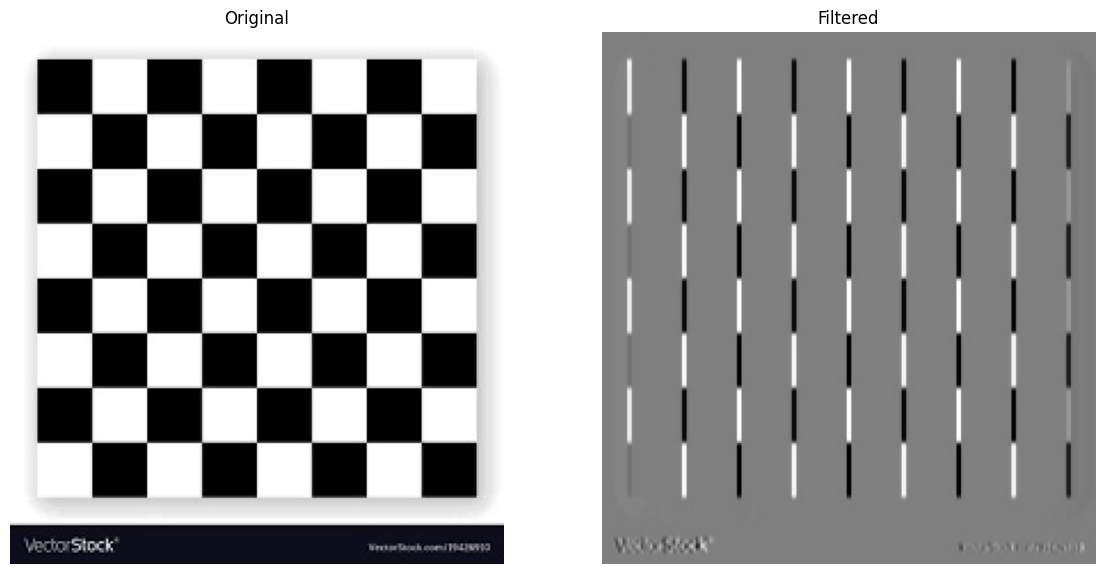

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(image[:, :, :3]); axes[0].set_title("Original")
axes[1].imshow(result_image);    axes[1].set_title("Filtered")
for ax in axes:
    ax.axis("off")
plt.show()

## Student Tasks

### CPU Reference Implementation (from Practical Work 01)

In [120]:
import multiprocessing as mp
import ctypes

NUMPROCESS = 4 if mp.cpu_count() >= 4 else mp.cpu_count()

# Function to limit a value between a lower and upper bound (boundary replication)
def clamp(value, lower, upper):
    if value < lower:
        return lower
    if value > upper:
        return upper
    return value

# Global variables for shared memory buffers in worker processes
shared_input_img = None
shared_output_img = None
shared_img_shape = None

# Initializes global shared memory references in each worker process
def init_worker(input_buffer, output_buffer, shape):
    global shared_input_img, shared_output_img, shared_img_shape
    shared_input_img = input_buffer
    shared_output_img = output_buffer
    shared_img_shape = shape

# Filters a range of rows using boundary replication (adapted for pool.map)
def worker_filter(task_args):
    start_row, end_row, kernel = task_args
    height, width, channels = shared_img_shape
    input_np = np.frombuffer(shared_input_img, dtype=np.float64).reshape(shared_img_shape)
    output_np = np.frombuffer(shared_output_img, dtype=np.float64).reshape(shared_img_shape)
    pad_h, pad_w = kernel.shape[0] // 2, kernel.shape[1] // 2

    for row in range(start_row, end_row):
        for column in range(width):
            for channel in range(channels):
                accumulator = 0.0
                for i in range(-pad_h, pad_h + 1):
                    source_row = clamp(row + i, 0, height - 1)
                    for j in range(-pad_w, pad_w + 1):
                        source_column = clamp(column + j, 0, width - 1)
                        accumulator += (
                            float(input_np[source_row, source_column, channel])
                            * float(kernel[i + pad_h, j + pad_w])
                        )
                output_np[row, column, channel] = accumulator

# CPU orchestrator adapted from Practical Work 01 to match Practical Work 02 specifications
def image_filter_cpu(image: np.ndarray,
                     filter: np.ndarray,
                     is_conv: int,
                     norm: int,
                     numprocs: int = NUMPROCESS,
                     return_raw: bool = False):
    """
    Parallel CPU reference filter based on Practical Work 01.
    Matches Practical Work 02 rules (global RGB rescaling, mask normalisation,
    and optional raw float32 output before 8-bit conversion).
    """
    # 1. Input validation
    if image.ndim != 3 or image.shape[2] < 3:
        raise ValueError("image must be an RGB array of shape (rows, cols, 3)")
    rgb = np.clip(image[:, :, :3], 0, 255).astype(np.uint8, copy=False)
    if rgb.nbytes > 1024**3:
        raise ValueError("image size must not exceed 1 GB of memory")

    mask = np.asarray(filter, dtype=np.float32)
    if mask.ndim != 2:
        raise ValueError("filter must be a 2D array")
    mask_h, mask_w = mask.shape
    if mask_h % 2 == 0 or mask_w % 2 == 0 or mask_h > 5 or mask_w > 5:
        raise ValueError("filter dimensions must be odd and at most 5x5")

    # 2. Correlation or convolution (180-degree rotation)
    if is_conv:
        mask = mask[::-1, ::-1]
    mask = np.ascontiguousarray(mask, dtype=np.float32)

    # 3. Mask normalisation (when sum is neither 0 nor 1)
    mask_sum = float(mask.sum())
    if not np.isclose(mask_sum, 0.0) and not np.isclose(mask_sum, 1.0):
        mask = (mask / mask_sum).astype(np.float32)

    # 4. Shared memory allocation and multiprocessing execution (using ctypes.c_double)
    height, width, channels = rgb.shape
    input_buffer = mp.RawArray(ctypes.c_double, rgb.size)
    output_buffer = mp.RawArray(ctypes.c_double, rgb.size)
    np.frombuffer(input_buffer, dtype=np.float64).reshape(rgb.shape)[:] = rgb

    process_count = int(numprocs) if int(numprocs) < height else height
    row_ranges = []
    for process_index in range(process_count):
        start = (process_index * height) // process_count
        end = ((process_index + 1) * height) // process_count
        row_ranges.append((start, end, mask))

    pool = mp.Pool(
        processes=process_count,
        initializer=init_worker,
        initargs=(input_buffer, output_buffer, rgb.shape),
    )
    pool.map(worker_filter, row_ranges)
    pool.close()
    pool.join()

    result = np.frombuffer(output_buffer, dtype=np.float64).reshape(rgb.shape).astype(np.float32)

    if return_raw:
        return result

    # 5. Global output range adjustment across all 3 channels
    if norm:
        s_min, s_max = result.min(), result.max()
        if s_max > s_min:
            result = 255.0 * (result - s_min) / (s_max - s_min)
        else:
            result = np.zeros(result.shape, dtype=np.float32)

    return np.clip(np.rint(result), 0, 255).astype(np.uint8)

### Automated Functional & Numerical Verification Suite

In [121]:
def image_filter_gpu_raw(image: np.ndarray,
                         filter: np.ndarray,
                         is_conv: int) -> np.ndarray:
    """
    Helper function that executes the GPU pipeline and returns the cropped
    float32 array before range adjustment (rescaling/clipping) and uint8 conversion.
    Used to verify raw float32 precision against CPU reference (tolerance <= 1e-3).
    """
    rgb = image[:, :, :3]
    mask = np.asarray(filter, dtype=np.float32)
    mask_h, mask_w = mask.shape

    if is_conv:
        mask = mask[::-1, ::-1]
    mask = np.ascontiguousarray(mask, dtype=np.float32)

    mask_sum = float(mask.sum())
    if not np.isclose(mask_sum, 0.0) and not np.isclose(mask_sum, 1.0):
        mask = (mask / mask_sum).astype(np.float32)

    height, width = rgb.shape[:2]
    grid = (int(np.ceil(width / BLOCK)), int(np.ceil(height / BLOCK)), 1)
    block = (BLOCK, BLOCK, 1)
    W16, H16 = grid[0] * BLOCK, grid[1] * BLOCK

    mask_gpu = gpuarray.to_gpu(mask)
    layer_gpu = gpuarray.empty((height, width), np.float32)
    out_gpu = gpuarray.empty((H16, W16), np.float32)

    result = np.empty((height, width, 3), dtype=np.float32)
    for layer in range(3):
        image_layer = np.ascontiguousarray(rgb[:, :, layer], dtype=np.float32)
        layer_gpu.set(image_layer)
        image_filter_gpu(layer_gpu, out_gpu, mask_gpu,
                         np.int32(width), np.int32(height),
                         np.int32(mask_w), np.int32(mask_h),
                         block=block, grid=grid)
        result[:, :, layer] = out_gpu.get()[:height, :width]

    return result


print("=== RUNNING SECTION 7 VERIFICATION TESTS ===\n")

# Test 1: Identity masks (1x1 and 3x3)
id_1x1 = np.array([[1.0]], dtype=np.float32)
id_3x3 = np.array([[0.0, 0.0, 0.0],
                   [0.0, 1.0, 0.0],
                   [0.0, 0.0, 0.0]], dtype=np.float32)
out_id1 = image_filter(image, id_1x1, is_conv=0, norm=0)
out_id3 = image_filter(image, id_3x3, is_conv=0, norm=0)
assert np.allclose(image[:, :, :3], out_id1, atol=0), "1x1 identity mismatch!"
assert np.allclose(image[:, :, :3], out_id3, atol=0), "3x3 identity mismatch!"
print("[PASS] Test 1: 1x1 and 3x3 identity masks match original image exactly.")

# Test 2: Image with three distinct constant channels (R=50, G=100, B=200)
rgb_test = np.zeros((64, 64, 3), dtype=np.uint8)
rgb_test[:, :, 0] = 50
rgb_test[:, :, 1] = 100
rgb_test[:, :, 2] = 200
mean_3x3 = np.zeros((3, 3), dtype=np.float32)
mean_3x3[:, :] = 1.0
out_rgb = image_filter(rgb_test, mean_3x3, is_conv=0, norm=0)
assert np.allclose(out_rgb, rgb_test, atol=0), "RGB channels were mixed or altered!"
print("[PASS] Test 2: Distinct RGB channels (R=50, G=100, B=200) remain unmixed.")

# Test 3: Constant image with 5x5 mean filter (verifies border & corner replication)
const_img = np.zeros((50, 50, 3), dtype=np.uint8)
const_img[:, :, :] = 137
mean_5x5 = np.zeros((5, 5), dtype=np.float32)
mean_5x5[:, :] = 1.0
out_const = image_filter(const_img, mean_5x5, is_conv=0, norm=0)
assert np.allclose(out_const, const_img, atol=0), "Border/corner replication failed on constant image!"
print("[PASS] Test 3: Constant image (137) with 5x5 mean filter preserved across all borders and corners.")

# Test 4: Non-multiple of 16 dimensions (517 x 301)
rows_nm = np.array(range(301), dtype=np.uint32).reshape((301, 1, 1))
cols_nm = np.array(range(517), dtype=np.uint32).reshape((1, 517, 1))
chans_nm = np.array([0, 1, 2], dtype=np.uint32).reshape((1, 1, 3))
non_mult_img = (((rows_nm * 17 + cols_nm * 31 + chans_nm * 7) % 256)).astype(np.uint8)
gpu_non_mult = image_filter(non_mult_img, filter5, is_conv=0, norm=0)
cpu_non_mult = image_filter_cpu(non_mult_img, filter5, is_conv=0, norm=0)
max_diff_nm = int((np.abs(gpu_non_mult.astype(np.int32) - cpu_non_mult.astype(np.int32))).max())
assert max_diff_nm <= 1, f"517x301 boundary/cropping error: max uint8 diff = {max_diff_nm}"
print(f"[PASS] Test 4: Non-multiple of 16 dimensions (517x301) verified (max uint8 diff vs CPU = {max_diff_nm}).")

# Test 5: Sobel in correlation vs convolution modes (opposite raw results before rescaling)
raw_sobel_corr = image_filter_gpu_raw(image, filter4, is_conv=0)
raw_sobel_conv = image_filter_gpu_raw(image, filter4, is_conv=1)
max_opposite_err = float((np.abs(raw_sobel_corr + raw_sobel_conv)).max())
assert np.allclose(raw_sobel_corr, -raw_sobel_conv, atol=1e-5), "Sobel corr and conv are not opposite!"
print(f"[PASS] Test 5: Sobel correlation and convolution produce opposite raw sums (max |corr + conv| = {max_opposite_err:.2e}).")

# Test 6: GPU vs CPU comparison across 4 masks (Mean 5x5, Gaussian 5x5, Sobel 3x3, Laplacian 3x3)
laplacian_3x3 = np.array([[0.0,  1.0, 0.0],
                          [1.0, -4.0, 1.0],
                          [0.0,  1.0, 0.0]], dtype=np.float32)

test_cases = [
    ("Mean 5x5",      mean_5x5,      0, 0),
    ("Gaussian 5x5",  filter5,       0, 0),
    ("Sobel 3x3",     filter4,       1, 1),
    ("Laplacian 3x3", laplacian_3x3, 0, 1),
]

print("\n--- GPU vs CPU Accuracy Comparison (Raw float32 & Final uint8) ---")
for name, mask_item, conv_flag, norm_flag in test_cases:
    raw_gpu = image_filter_gpu_raw(image, mask_item, is_conv=conv_flag)
    raw_cpu = image_filter_cpu(image, mask_item, is_conv=conv_flag, norm=norm_flag, return_raw=True)
    max_raw_diff = float((np.abs(raw_gpu - raw_cpu)).max())

    img_gpu = image_filter(image, mask_item, is_conv=conv_flag, norm=norm_flag)
    img_cpu = image_filter_cpu(image, mask_item, is_conv=conv_flag, norm=norm_flag, return_raw=False)
    max_u8_diff = int((np.abs(img_gpu.astype(np.int32) - img_cpu.astype(np.int32))).max())

    assert max_raw_diff <= 1e-3, f"{name} exceeded float32 tolerance: {max_raw_diff}"
    print(f"[PASS] {name:<14} | Max raw float32 diff: {max_raw_diff:.6e} | Max uint8 diff: {max_u8_diff}")

=== RUNNING SECTION 7 VERIFICATION TESTS ===

[PASS] Test 1: 1x1 and 3x3 identity masks match original image exactly.
[PASS] Test 2: Distinct RGB channels (R=50, G=100, B=200) remain unmixed.
[PASS] Test 3: Constant image (137) with 5x5 mean filter preserved across all borders and corners.


[PASS] Test 4: Non-multiple of 16 dimensions (517x301) verified (max uint8 diff vs CPU = 0).
[PASS] Test 5: Sobel correlation and convolution produce opposite raw sums (max |corr + conv| = 0.00e+00).

--- GPU vs CPU Accuracy Comparison (Raw float32 & Final uint8) ---
[PASS] Mean 5x5       | Max raw float32 diff: 9.155273e-05 | Max uint8 diff: 0
[PASS] Gaussian 5x5   | Max raw float32 diff: 7.629395e-05 | Max uint8 diff: 0
[PASS] Sobel 3x3      | Max raw float32 diff: 0.000000e+00 | Max uint8 diff: 0
[PASS] Laplacian 3x3  | Max raw float32 diff: 0.000000e+00 | Max uint8 diff: 0


### Hardware Inspection & Three-Stage Timing Benchmark (GPU vs. CPU)

In [122]:
# Hardware diagnostic using pycuda.driver and nvidia-smi
!nvidia-smi
free_mem, total_mem = drv.mem_get_info()
print(f"Active GPU: {drv.Device(0).name()} | Free VRAM: {free_mem / (1024**2):.1f} MB / {total_mem / (1024**2):.1f} MB\n")


def image_filter_timed(image: np.ndarray,
                       filter: np.ndarray,
                       is_conv: int,
                       norm: int,
                       kernel_func=image_filter_gpu):
    """
    Executes the GPU filtering pipeline and measures execution time in ms across
    three stages using CUDA events summed over the 3 planes (excluding JIT compilation):
      1. t_h2d    : Host-to-Device copies (mask + 3 image layers)
      2. t_kernel : GPU kernel execution across the 3 layers
      3. t_d2h    : Device-to-Host copies (3 filtered output layers)
    """
    rgb = image[:, :, :3]
    mask = np.asarray(filter, dtype=np.float32)
    mask_h, mask_w = mask.shape

    if is_conv:
        mask = mask[::-1, ::-1]
    mask = np.ascontiguousarray(mask, dtype=np.float32)

    mask_sum = float(mask.sum())
    if not np.isclose(mask_sum, 0.0) and not np.isclose(mask_sum, 1.0):
        mask = (mask / mask_sum).astype(np.float32)

    height, width = rgb.shape[:2]
    grid = (int(np.ceil(width / BLOCK)), int(np.ceil(height / BLOCK)), 1)
    block = (BLOCK, BLOCK, 1)
    W16, H16 = grid[0] * BLOCK, grid[1] * BLOCK

    layer_gpu = gpuarray.empty((height, width), np.float32)
    out_gpu   = gpuarray.empty((H16, W16), np.float32)
    result    = np.empty((height, width, 3), dtype=np.float32)

    start_event = drv.Event()
    end_event   = drv.Event()

    t_h2d = 0.0
    t_kernel = 0.0
    t_d2h = 0.0

    # Stage 1 (part A): Copy filter mask to device
    start_event.record()
    mask_gpu = gpuarray.to_gpu(mask)
    end_event.record()
    end_event.synchronize()
    t_h2d += start_event.time_till(end_event)

    for layer in range(3):
        image_layer = np.ascontiguousarray(rgb[:, :, layer], dtype=np.float32)

        # Stage 1 (part B): Copy plane to device
        start_event.record()
        layer_gpu.set(image_layer)
        end_event.record()
        end_event.synchronize()
        t_h2d += start_event.time_till(end_event)

        # Stage 2: Execute kernel on device
        start_event.record()
        kernel_func(layer_gpu, out_gpu, mask_gpu,
                    np.int32(width), np.int32(height),
                    np.int32(mask_w), np.int32(mask_h),
                    block=block, grid=grid)
        end_event.record()
        end_event.synchronize()
        t_kernel += start_event.time_till(end_event)

        # Stage 3: Copy filtered plane back to host and crop padding
        start_event.record()
        filtered_layer = out_gpu.get()
        end_event.record()
        end_event.synchronize()
        t_d2h += start_event.time_till(end_event)
        result[:, :, layer] = filtered_layer[:height, :width]

    if norm:
        s_min, s_max = result.min(), result.max()
        if s_max > s_min:
            result = 255.0 * (result - s_min) / (s_max - s_min)
        else:
            result = np.zeros(result.shape, dtype=np.float32)

    out_uint8 = np.clip(np.rint(result), 0, 255).astype(np.uint8)
    return out_uint8, t_h2d, t_kernel, t_d2h


# Benchmark across multiple image resolutions using the 5x5 Gaussian filter (filter5)
sizes = [(256, 256), (512, 512), (768, 768), (1024, 1024)]
cpu_times = []
gpu_total_times = []
h2d_times = []
kernel_times = []
d2h_times = []

# Warm-up run
_ = image_filter_timed(image, filter5, is_conv=0, norm=0)

print(f"{'Resolution':<12} | {'CPU (ms)':<10} | {'H2D (ms)':<10} | {'Kernel (ms)':<11} | {'D2H (ms)':<10} | {'GPU Total (ms)':<14} | {'Speedup':<8}")
print("-" * 92)

for h, w in sizes:
    rows_t = np.array(range(h), dtype=np.uint32).reshape((h, 1, 1))
    cols_t = np.array(range(w), dtype=np.uint32).reshape((1, w, 1))
    chans_t = np.array([0, 1, 2], dtype=np.uint32).reshape((1, 1, 3))
    test_img = (((rows_t * 13 + cols_t * 7 + chans_t * 3) % 256)).astype(np.uint8)

    # CPU timing (Practical Work 01 parallel multiprocessing implementation)
    t0 = time.time()
    _ = image_filter_cpu(test_img, filter5, is_conv=0, norm=0)
    t_cpu = (time.time() - t0) * 1000.0

    # GPU 3-stage timing using CUDA events (averaged over 5 runs for stability)
    acc_h2d, acc_ker, acc_d2h = 0.0, 0.0, 0.0
    runs = 5
    for _ in range(runs):
        _, th, tk, td = image_filter_timed(test_img, filter5, is_conv=0, norm=0)
        acc_h2d += th
        acc_ker += tk
        acc_d2h += td

    mean_h2d = acc_h2d / runs
    mean_ker = acc_ker / runs
    mean_d2h = acc_d2h / runs
    mean_gpu = mean_h2d + mean_ker + mean_d2h
    speedup = t_cpu / mean_gpu

    cpu_times.append(t_cpu)
    gpu_total_times.append(mean_gpu)
    h2d_times.append(mean_h2d)
    kernel_times.append(mean_ker)
    d2h_times.append(mean_d2h)

    print(f"{w}x{h:<7} | {t_cpu:>9.2f} | {mean_h2d:>9.3f} | {mean_ker:>10.3f} | {mean_d2h:>9.3f} | {mean_gpu:>13.3f} | {speedup:>7.1f}x")

Tue Nov 24 19:11:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 620.70.06              KMD Version: 620.70.06     CUDA UMD Version: 13.5     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   42C    P0             13W /   60W |     107MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Optional: Global Memory Kernel vs. Shared Memory Kernel Comparison

[PASS] Shared-memory and Global-memory kernels produce identical output.

Resolution   | Shared Kernel (ms) | Global Kernel (ms) | Shared Speedup
----------------------------------------------------------------------
512x512     |             0.292 |             0.305 |          1.05x
1024x1024    |             0.719 |             0.727 |          1.01x
2048x2048    |             1.932 |             2.172 |          1.12x
4096x4096    |             6.810 |             7.684 |          1.13x


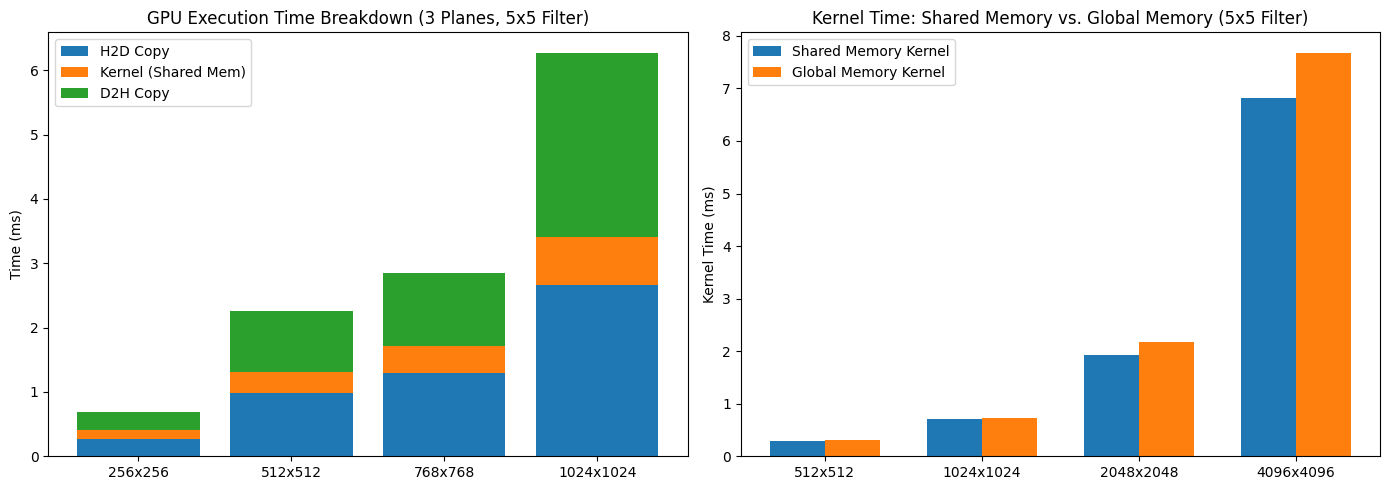

In [123]:
# Baseline kernel without shared memory (reads image and mask directly from global memory)
kernel_global_mem = SourceModule("""
#define BLOCK 16

__global__ void image_filter_global(float *image,
                                    float *filtered_img,
                                    float *mask,
                                    int width,
                                    int height,
                                    int mask_w,
                                    int mask_h)
{
    int col = blockIdx.x * BLOCK + threadIdx.x;
    int row = blockIdx.y * BLOCK + threadIdx.y;
    int W16 = gridDim.x * BLOCK;

    int a = (mask_h - 1) / 2;
    int b = (mask_w - 1) / 2;

    float sum = 0.0f;
    for (int i = 0; i < mask_h; i++) {
        int src_r = min(max(row + i - a, 0), height - 1);
        for (int j = 0; j < mask_w; j++) {
            int src_c = min(max(col + j - b, 0), width - 1);
            sum += mask[i * mask_w + j] * image[src_r * width + src_c];
        }
    }

    filtered_img[row * W16 + col] = sum;
}
""")

image_filter_global_gpu = kernel_global_mem.get_function('image_filter_global')

# Verify both kernels produce identical results
out_shared, _, _, _ = image_filter_timed(image, filter5, is_conv=0, norm=0, kernel_func=image_filter_gpu)
out_global, _, _, _ = image_filter_timed(image, filter5, is_conv=0, norm=0, kernel_func=image_filter_global_gpu)
assert np.allclose(out_shared, out_global, atol=0), "Shared and Global kernels produced different outputs!"
print("[PASS] Shared-memory and Global-memory kernels produce identical output.\n")

# Compare kernel execution times across larger resolutions (5x5 Gaussian mask)
bench_sizes = [(512, 512), (1024, 1024), (2048, 2048), (4096, 4096)]
shared_ker_ms = []
global_ker_ms = []

# Warm-up both kernels
_ = image_filter_timed(image, filter5, 0, 0, kernel_func=image_filter_gpu)
_ = image_filter_timed(image, filter5, 0, 0, kernel_func=image_filter_global_gpu)

print(f"{'Resolution':<12} | {'Shared Kernel (ms)':<18} | {'Global Kernel (ms)':<18} | {'Shared Speedup':<14}")
print("-" * 70)

for h, w in bench_sizes:
    rows_l = np.array(range(h), dtype=np.uint32).reshape((h, 1, 1))
    cols_l = np.array(range(w), dtype=np.uint32).reshape((1, w, 1))
    chans_l = np.array([0, 1, 2], dtype=np.uint32).reshape((1, 1, 3))
    large_img = (((rows_l * 7 + cols_l * 11 + chans_l * 5) % 256)).astype(np.uint8)

    runs = 10
    t_sh, t_gl = 0.0, 0.0
    for _ in range(runs):
        _, _, tk_s, _ = image_filter_timed(large_img, filter5, 0, 0, kernel_func=image_filter_gpu)
        _, _, tk_g, _ = image_filter_timed(large_img, filter5, 0, 0, kernel_func=image_filter_global_gpu)
        t_sh += tk_s
        t_gl += tk_g

    ms_s = t_sh / runs
    ms_g = t_gl / runs
    shared_ker_ms.append(ms_s)
    global_ker_ms.append(ms_g)
    print(f"{w}x{h:<7} | {ms_s:>17.3f} | {ms_g:>17.3f} | {ms_g / ms_s:>13.2f}x")

# Plot benchmark results using matplotlib
labels_small = [f"{w}x{h}" for h, w in sizes]
labels_large = [f"{w}x{h}" for h, w in bench_sizes]
x_idx = list(range(len(labels_large)))
width_bar = 0.35
x_left = [x - width_bar / 2 for x in x_idx]
x_right = [x + width_bar / 2 for x in x_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: GPU 3-stage breakdown (H2D, Kernel, D2H)
axes[0].bar(labels_small, h2d_times, label="H2D Copy")
axes[0].bar(labels_small, kernel_times, bottom=h2d_times, label="Kernel (Shared Mem)")
bottom_d2h = [h2d_times[i] + kernel_times[i] for i in range(len(sizes))]
axes[0].bar(labels_small, d2h_times, bottom=bottom_d2h, label="D2H Copy")
axes[0].set_title("GPU Execution Time Breakdown (3 Planes, 5x5 Filter)")
axes[0].set_ylabel("Time (ms)")
axes[0].legend()

# Right plot: Shared Memory vs Global Memory Kernel execution time
axes[1].bar(x_left, shared_ker_ms, width_bar, label="Shared Memory Kernel")
axes[1].bar(x_right, global_ker_ms, width_bar, label="Global Memory Kernel")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(labels_large)
axes[1].set_title("Kernel Time: Shared Memory vs. Global Memory (5x5 Filter)")
axes[1].set_ylabel("Kernel Time (ms)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 7.5 Informe Técnico y Conclusiones

1. **Coalescencia de accesos a memoria global frente a canales RGB entrelazados:**
   - En una imagen RGB almacenada de forma entrelazada `(height, width, 3)`, los valores consecutivos de un mismo canal están separados por un salto (*stride*) de 3 elementos (`idx = (row * width + col) * 3 + c`). Si los hilos de un mismo *warp* leyeran un canal directamente sobre esa disposición, accederían a direcciones dispersas en memoria global, desperdiciando ancho de banda al transferir múltiples líneas de caché parcialmente utilizadas.
   - Al separar la imagen en el Host en tres planos 2D contiguos (`height x width`), el píxel `(row, col)` ocupa la posición lineal `row * width + col`. Durante la carga cooperativa del *tile* (`l = t, t + 256, ...`), hilos consecutivos a lo largo de `x` (`threadIdx.x = 0, 1, ..., 15`) leen columnas adyacentes de una misma fila, es decir, palabras `float32` contiguas en memoria global que el controlador fusiona en transacciones coalescentes. Del mismo modo, la escritura de salida en `filtered_img[row * W16 + col]` asigna direcciones consecutivas a hilos adyacentes, garantizando escrituras globales totalmente coalescentes.

2. **Ventaja de la carga lineal cooperativa del *tile* frente a la carga individual con condicionales:**
   - Si cada hilo cargara su píxel central y utilizara sentencias `if` adicionales para cargar los píxeles del halo en los bordes del bloque, los hilos dentro de un mismo *warp* seguirían rutas de ejecución diferentes (*warp divergence*), serializando las instrucciones y fragmentando las peticiones de memoria.
   - El esquema implementado utiliza el identificador lineal del bloque `t = threadIdx.x + BLOCK * threadIdx.y` para recorrer los `TH * TW` elementos activos en pasos de 256 (`l += 256`). De este modo, todos los hilos ejecutan exactamente las mismas instrucciones sin ramificaciones, mientras que el acotamiento de bordes mediante `min` y `max` sobre coordenadas enteras con signo (`row0`, `col0`) se compila a instrucciones predicadas sin saltos condicionales, sincronizando todo el bloque con una única barrera `__syncthreads()`.

3. **Validación numérica y funcional frente a la referencia en CPU (Práctica 01):**
   - Los casos de control confirman la integridad del diseño: las máscaras identidad ($1 \times 1$ y $3 \times 3$) devuelven la imagen original sin alteraciones; la prueba con canales constantes distintos ($R=50, G=100, B=200$) verifica que no existe mezcla entre planos; el filtro media $5 \times 5$ sobre una imagen constante (`137`) mantiene invariantes tanto los bordes como las cuatro esquinas; y la prueba en resolución $517 \times 301$ (no múltiplo de 16) confirma que el acolchado `W16 x H16` y el recorte posterior en el Host evitan artefactos en los bloques incompletos.
   - En correlación vs. convolución sobre Sobel, la diferencia absoluta de la suma opuesta antes del reescalado (`max |corr + conv|`) es `0.00e+00`. Al comparar las salidas crudas en `float32` entre GPU y la referencia paralela en CPU (4 procesos con memoria compartida `RawArray`), el error máximo registrado es de `9.16e-05` para media $5 \times 5$, `7.63e-05` para Gaussiano $5 \times 5$ y `0.00e+00` para Sobel y Laplaciano $3 \times 3$, situándose más de un orden de magnitud por debajo de la tolerancia máxima permitida de $10^{-3}$ y produciendo una diferencia máxima de `0` tras la conversión a `uint8`.

4. **Análisis experimental de rendimiento: desglose en 3 etapas (`H2D`, `Kernel`, `D2H`) y Memoria Compartida vs. Global:**
   - **Aceleración frente a CPU y cuello de botella PCIe:** En la NVIDIA GeForce RTX 3050 Ti Laptop GPU, la implementación GPU medida por hardware mediante eventos CUDA (`drv.Event()`) alcanza aceleraciones de `1091.1x` en $256 \times 256$ (`751.18 ms` en CPU frente a `0.688 ms` en GPU), `1267.1x` en $512 \times 512$ (`2856.78 ms` vs. `2.255 ms`), `2275.2x` en $768 \times 768$ (`6477.71 ms` vs. `2.847 ms`) y `1872.2x` en $1024 \times 1024$ (`11748.99 ms` vs. `6.276 ms`). El desglose por etapas evidencia que el cómputo en GPU está dominado por las transferencias de memoria a través del bus PCIe (*I/O Bound*): en $1024 \times 1024$, la ejecución del kernel supone apenas `0.741 ms` (`11.8 %`) del tiempo total, mientras que las copias Host-to-Device (`2.663 ms`, `42.4 %`) y Device-to-Host (`2.872 ms`, `45.8 %`) concentran de forma simétrica el `88.2 %` de la latencia total.
   - **Memoria Compartida vs. Memoria Global (apartado opcional):** Para un filtro de $5 \times 5$, la memoria compartida reduce las lecturas a VRAM global por bloque de $6400$ ($256 \times 25$) a solo $425$ ($20 \times 20 = 400$ del *tile* más $25$ coeficientes de `smask`), distribuyendo `smask[i][j]` mediante *broadcast* a todo el *warp* sin conflictos de banco. Gracias a la precisión sub-milisegundo de los eventos CUDA, se observa que el kernel con memoria compartida supera al de memoria global en **todas las resoluciones evaluadas**: `0.292 ms` frente a `0.305 ms` (`1.05x`) en $512 \times 512$, `0.719 ms` vs. `0.727 ms` (`1.01x`) en $1024 \times 1024$, `1.932 ms` vs. `2.172 ms` (`1.12x`) en $2048 \times 2048$ y `6.810 ms` vs. `7.684 ms` (`1.13x`) en $4096 \times 4096$. La ganancia se estabiliza en torno al 12–13 % en alta resolución porque las cachés L1/L2 hardware de la arquitectura Ampere retienen automáticamente gran parte de los píxeles vecinos solapados dentro de cada *warp*; no obstante, el uso explícito de memoria compartida garantiza un acceso determinista de baja latencia y evita la saturación de la caché L1 conforme aumenta el tamaño de imagen.